In [24]:
import functools
import time

# This is a timer wrapper so we can compare how much longer
# Monte Carlo simulations take vs Viete's product

def time_me(func):
    @functools.wraps(func)
    def timer(*args, **kwargs):
        start = time.perf_counter()
        values = func(*args, **kwargs)
        timer.elapsed = time.perf_counter() - start
        return values
    return timer

### 1. Write a program to make a statistical estimate for π using one of the two methods suggested in ‘Maths13’

I will estimate $\pi$ using a Monte-Carlo simualtion of a $[1,1]$ square.

In [25]:
import numpy as np

seed = np.random.default_rng(1234)

def estimate_pi(N, r=1.0):
    x = seed.random(N)
    y = seed.random(N)
    inside = np.count_nonzero(x**2 + y**2 < r**2)
    return 4 / r**2 * inside / N


for N in [10**2, 10**4, 10**6, 10**8]:
    pi_hat = estimate_pi(N)
    print(f"N = {N}: pi_hat = {pi_hat:.5f}, error = {pi_hat - np.pi:+.5f}")

N = 100: pi_hat = 3.16000, error = +0.01841
N = 10000: pi_hat = 3.13680, error = -0.00479
N = 1000000: pi_hat = 3.13932, error = -0.00227
N = 100000000: pi_hat = 3.14136, error = -0.00023


### 2. How accurate is the Monte Carlo?

Repeat pi estimate many times, fit the spread, and check 1.64/sqrt(N)

In [26]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm

plot_dir = "out/plots"
repeats = 2000
p = np.pi / 4

# Run the estimate lots of times and fit a Gaussian.
N = 10_000
estimates = []

for _ in range(repeats):
    estimates.append(estimate_pi(N))

mean, sigma = norm.fit(estimates)
expected_sigma = 4 * np.sqrt(p * (1 - p) / N)

print(f"N = {N}")
print(f"Mean pi: {mean:.4f}")
print(f"Standard deviation: {sigma:.4f}")
print(f"Expected standard deviation: {expected_sigma:.4f}")

# Each bin contains eight possible estimates, spaced by 4/N.
step = 4 / N
first_count = round(min(estimates) / step)
last_count = round(max(estimates) / step)
bins = np.arange(first_count - 0.5, last_count + 8, 8) * step

x = np.linspace(min(estimates), max(estimates), 300)

plt.figure()
plt.hist(estimates, bins=bins, density=True, alpha=0.5,
         label=f"{repeats} runs")
plt.plot(x, norm.pdf(x, mean, sigma), label="Gaussian fit")
plt.axvline(np.pi, color="black", linestyle="--", label=r"$\pi$")
plt.xlabel(r"$\hat{\pi}$")
plt.ylabel("Density")
plt.legend()
plt.tight_layout()
plt.savefig(f"{plot_dir}/pi_histogram.png", dpi=150)
plt.close()


# See how the standard deviation changes with N.
sample_sizes = np.array([100, 300, 1000, 3000, 10_000, 30_000])
sigmas = []

for N in sample_sizes:
    estimates = []

    for _ in range(repeats):
        estimates.append(estimate_pi(N))

    sigmas.append(np.std(estimates))

expected_sigmas = 4 * np.sqrt(p * (1 - p) / sample_sizes)
slope, intercept = np.polyfit(np.log(sample_sizes), np.log(sigmas), 1)

print(f"\nMeasured slope: {slope:.3f}")
print("Expected slope: -0.5")

plt.figure()
plt.loglog(sample_sizes, sigmas, "o", label="Measured spread")
plt.loglog(sample_sizes, expected_sigmas, label="Expected spread")
plt.xlabel("$N$")
plt.ylabel(r"$\sigma_{\hat{\pi}}$")
plt.legend()
plt.tight_layout()
plt.savefig(f"{plot_dir}/pi_scaling.png", dpi=150)
plt.close()


# Compare the relative error for two different radii.
N = 10_000

for radius in [1.0, np.sqrt(2 / 3)]:
    estimates = []

    for _ in range(repeats):
        estimates.append(estimate_pi(N, radius))

    relative_error = np.std(estimates) / np.pi
    p_inside = np.pi * radius**2 / 4

    measured = relative_error * np.sqrt(N)
    expected = np.sqrt((1 - p_inside) / p_inside)

    print(f"\nRadius squared: {radius**2:.3f}")
    print(f"Relative error * sqrt(N): {measured:.3f}")
    print(f"Expected value: {expected:.3f}")

N = 10000
Mean pi: 3.1405
Standard deviation: 0.0164
Expected standard deviation: 0.0164

Measured slope: -0.497
Expected slope: -0.5

Radius squared: 1.000
Relative error * sqrt(N): 0.514
Expected value: 0.523

Radius squared: 0.667
Relative error * sqrt(N): 0.968
Expected value: 0.954


In [27]:
import numpy as np

# Estimate pi using the first n_factors factors of Viete's product.

def viete_product(n_factors):

    if n_factors < 1:
        return 0
    
    x = 0
    product = 1

    for n in range(1, n_factors + 1):

        x = np.sqrt((1 + x) / 2)
        product = product * x

    return 2 / product


# Use our timer wrapper from before to show how much faster this method is!
timed_viete_product = time_me(viete_product)

n_factors = 7

pi_hat = timed_viete_product(n_factors)
error = pi_hat - np.pi
elapsed = timed_viete_product.elapsed

print(f"Vieta {n_factors} factors: pi_hat = {pi_hat:.5}, error = {error:.3}, elapsed = {elapsed:.3}")

Vieta 7 factors: pi_hat = 3.1415, error = -7.89e-05, elapsed = 3.33e-05


You can see from the results that Viete's product method is *much* quicker to converge. With 7 factors, it reaches an error in the order of 1-e5 in just ~5e-5 seconds. That's about 1,000,000 times faster than Monte-Carlo implementation on my laptop, which needed N=1e8 to converge with this error!

### 3. The 1D Ising model: internal energy per spin

I use a ring of 100 spins, so the first and last spins are neighbours (periodic boundaries). There is no external magnetic field. I set $J=1$ and $k_B=1$, so temperature is measured in units of $J/k_B$.

For a ferromagnet with positive $J$, I use
$$E=-J\sum_{i=0}^{N-1}s_i s_{i+1}, \qquad s_N=s_0.$$
Each bond is counted once. This uses a minus sign so aligned spins have lower energy; the positive-sign Hamiltonian in the project sheet would require a negative coupling for a ferromagnet.

Flipping spin $s_i$ changes the energy by
$$\Delta E=2Js_i(s_{i-1}+s_{i+1}).$$
I accept the flip if $\Delta E\leq0$; otherwise I accept it with probability $e^{-\Delta E/T}$.

One sweep means $N$ randomly chosen spin-flip attempts. At each temperature I start with aligned spins, discard 1,000 sweeps to allow equilibration, then average the energy over 3,000 sweeps. Starting aligned avoids slow removal of domain walls at very low temperatures.

For comparison, the exact result for an infinite chain is $e(T)=-J\tanh(J/T)$. The simulation uses a finite ring, so small finite-size differences are possible. Successive measurements are correlated; these sweep counts are a starting choice, and increasing them checks convergence.


In [28]:
import numpy as np
import matplotlib.pyplot as plt

ising_rng = np.random.default_rng(1234)


def total_energy(spins, J):
    energy = 0
    for i in range(len(spins)):
        energy -= J * spins[i] * spins[(i + 1) % len(spins)]
    return energy


def metropolis_sweep(spins, T, J):
    N = len(spins)
    for _ in range(N):
        i = ising_rng.integers(N)
        left = spins[(i - 1) % N]
        right = spins[(i + 1) % N]
        delta_energy = 2 * J * spins[i] * (left + right)

        if (delta_energy <= 0) or (ising_rng.random() < np.exp(-delta_energy / T)):
            spins[i] *= -1


def simulate_ising(T, N, J, equilibration_sweeps, measurement_sweeps):
    spins = np.ones(N, dtype=int)

    for _ in range(equilibration_sweeps):
        metropolis_sweep(spins, T, J)

    energies = []
    for _ in range(measurement_sweeps):
        metropolis_sweep(spins, T, J)
        energies.append(total_energy(spins, J))

    energies = np.array(energies)
    mean_energy = np.mean(energies)
    mean_energy_squared = np.mean(energies**2)

    energy_per_spin = mean_energy / N
    specific_heat = (mean_energy_squared - mean_energy**2) / (N * T**2)
    return energy_per_spin, specific_heat


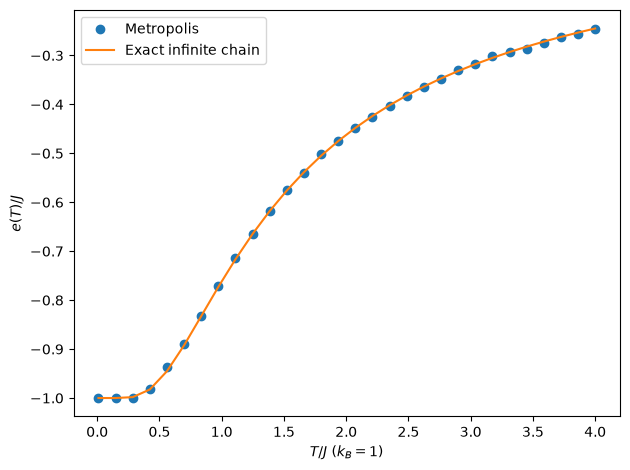

In [29]:
J = 1.0
N = 100
equilibration_sweeps = 1000
measurement_sweeps = 3000
temperatures = np.linspace(0.01, 4.0, 30) * J
mean_energies = []
specific_heats = []

for T in temperatures:
    energy, specific_heat = simulate_ising(T, N, J, equilibration_sweeps, measurement_sweeps)
    mean_energies.append(energy)
    specific_heats.append(specific_heat)

exact_energies = -J * np.tanh(J / temperatures)

plt.figure()
plt.plot(temperatures / J, np.array(mean_energies) / J, "o", label="Metropolis")
plt.plot(temperatures / J, exact_energies / J, label="Exact infinite chain")
plt.xlabel(r"$T/J$ ($k_B=1$)")
plt.ylabel(r"$e(T)/J$")
plt.legend()
plt.tight_layout()

plt.savefig(f"{plot_dir}/ising_1d_energy.png", dpi=150)
plt.show()


### b) Specific heat per spin

Specific heat tells us how much the average energy changes when the temperature increases. We can also calculate it from how much the energy fluctuates at a fixed temperature:

$$C(T)=\frac{\langle E^2\rangle-\langle E\rangle^2}{N k_B T^2}.$$

Here $E$ is the total energy of the ring. $\langle E^2\rangle$ means square each measured energy, then average; $\langle E\rangle^2$ means average the energies, then square. Their difference measures the spread of the energies. We divide by $N$ to get specific heat per spin, and use $k_B=1$ as before.

The simulation above now returns both energy per spin and specific heat from the same measurements. Run the function and temperature-loop cells again before plotting below.

For comparison, the infinite-chain result is
$$\frac{C(T)}{k_B}=\left(\frac{J}{k_B T}\right)^2\frac{1}{\cosh^2(J/(k_B T))}.$$
Specific heat can be noisier than mean energy because it depends on the spread of the measurements. At very low temperatures, almost no flips are accepted and the measured specific heat can be zero.


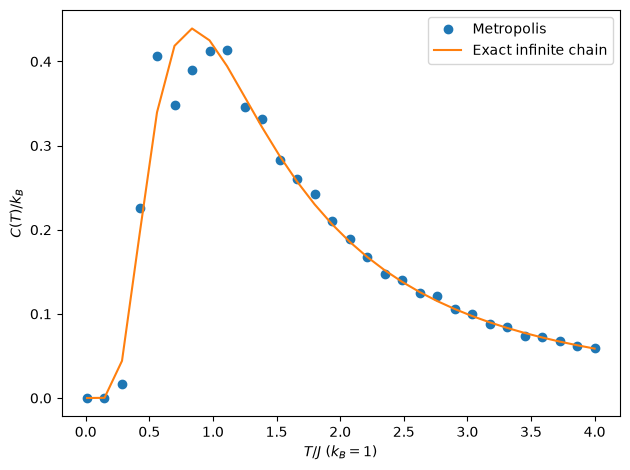

In [30]:
exact_specific_heats = (J / temperatures)**2 / np.cosh(J / temperatures)**2

plt.figure()
plt.plot(temperatures / J, specific_heats, "o", label="Metropolis")
plt.plot(temperatures / J, exact_specific_heats, label="Exact infinite chain")
plt.xlabel(r"$T/J$ ($k_B=1$)")
plt.ylabel(r"$C(T)/k_B$")
plt.legend()
plt.tight_layout()
plt.savefig(f"{plot_dir}/ising_1d_specific_heat.png", dpi=150)
plt.show()
